**Instructions:**

- Do not write your name on the assignment. Be careful about any warnings that might display some file path with your name included.
- Receiving help from classmates and/or ideas from Generative AI is allowed. **However, you must submit your own original work.**
- For questions that require coding, you need to write the relevant code and display its output. Your output should either be the direct answer to the question or clearly display the answer in it.
- For questions that require a written answer (sometimes along with the code), you need to put your answer in a Markdown cell. Writing the answer as a comment or as a print line is not acceptable.
- You need to render this file as HTML using Quarto and submit the HTML file. **Please note that this is a requirement and not optional.** A submission cannot be graded until it is properly rendered.

Import all the libraries and tools you need below.

In [48]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

## 1) Preprocessing (5 points)

### a)

Read the data from **tumor_classification.csv**. Each observation represents numeric measurements taken from the biopsy image of a patient. The `diagnosis` variable represents if the tumor is benign (`B`) or malignant (`M`) and it is the response/target variable. All the other variables, except for `id`, are the features.

Separate the response and the features.

**(1.5 points)**

In [5]:
df = pd.read_csv("tumor_classification.csv")

x = df.drop(columns=["diagnosis", "id"])
Y = df["diagnosis"]

### b)

Save the feature names to a new variable. It will be used later in this assignment. **(1.5 points)**

In [7]:
features = x.columns

### c)

Scale the features. Note that this is a bit different than what you have done in the previous assignments. You are scaling the full dataset before splitting it into training and test sets. **(2 points)**

In [9]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(x)

## 2) Principal Component Analysis (PCA) (50 points)

Answer the following questions by creating different [PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html) objects with the **scaled data**.

### a)

If the data is reduced to **five** dimensions, what percentage of its variance is kept? **(10 points)**

In [15]:
pca_5_dimension = PCA(n_components=5)
X_pca_5 = pca_5_dimension.fit_transform(X_scaled)
pca_5_dimension.explained_variance_ratio_.sum() * 100

# 84.73

84.73427431674604

### b)

How many dimensions are necessary to keep 99% of the variance in the data? **(10 points)**

In [ ]:
pca_99_variance = PCA(n_components=0.99)
X_pca_99_variance = pca_99_variance.fit_transform(X_scaled)

pca_99_variance.n_components_

# 17

17

### c)

To visualize the dimensionality-variance trade-off better, create a bar plot that shows the proportion of total variance each Principal Component (PC) holds. **(15 points)**

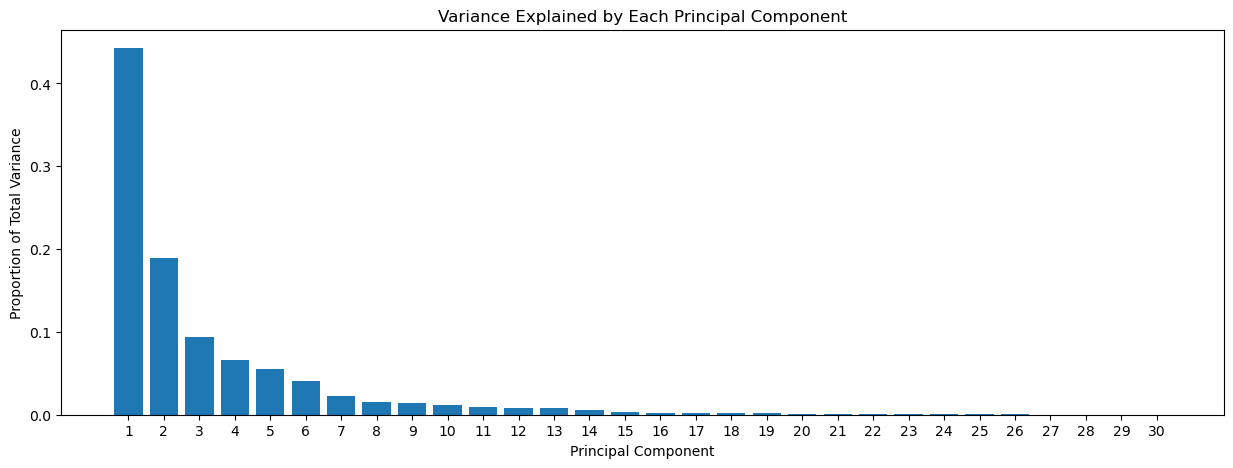

In [40]:
pca_all = PCA()
pca_all.fit(X_scaled)

variance_ratios = pca_all.explained_variance_ratio_

plt.figure(figsize=(15, 5))
plt.bar(range(1, 31), variance_ratios)
plt.xlabel("Principal Component")
plt.ylabel("Proportion of Total Variance")
plt.title("Variance Explained by Each Principal Component")

plt.xticks(range(1, 31))
plt.show()

### d)

For the first three PCs, find and print the names of the three features with the most contribution. (You need to print nine feature names in total.) Do you see a pattern in the names? Are there any features that appear (in the top three) for more than one PC? Why or why not? **(15 points)**

**Hint:** [argsort](https://numpy.org/doc/2.1/reference/generated/numpy.argsort.html) function can be helpful.

In [45]:
for i in range(3):
    weights = abs(pca_all.components_[i])
    top3 = np.argsort(weights)[-3:]

    print(f"PC{i + 1}: {features[top3].tolist()}")

PC1: ['concave points_worst', 'concavity_mean', 'concave points_mean']
PC2: ['fractal_dimension_worst', 'fractal_dimension_se', 'fractal_dimension_mean']
PC3: ['symmetry_se', 'smoothness_se', 'texture_se']


The pattern is that the first principal component has the most significant features related to concave points and concavity, the second PC has the features related to fractal dimensions and the third PC has the features related to standar error measurement. No features appear in the top three for more than PC. This is because PCA creates different components that capture different directions of variance in the data. However, features can still contribute to more than one PC because the components are orthogonal, not necessarily the individual features.

## 3) PCA with Logistic Regression (45 points)

### a)

Split the data into **stratified** training and test sets with a 80%-20% ratio and `random_state=12`. Keep in mind that the input features should already be scaled. **(2 points)**

In [47]:
X_train, X_test, y_train, y_test = train_test_split(X_scaled, Y, test_size=0.2, random_state=12, stratify=Y)

### b)

Create a Logistic Regression model **without any penalty** and with `random_state=12`.

This dataset is easily classifiable, so leave all other inputs and the decision threshold as default. Train the model and print the test accuracy and the test confusion matrix. You will need to compare the results in this part with the following parts.

**(5 points)**

In [49]:
model = LogisticRegression(penalty=None, random_state=12)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))

Test accuracy: 0.956140350877193
Confusion matrix:
[[67  5]
 [ 0 42]]


### c)

Repeat Parts a and b four times (with the same `random_state`): Before the train-test split, reduce the dimensionality of the data with **99%, 97%, 95% and 90%** of the variance kept, respectively. Afterwards, take the same steps as in Parts a and b.

Print the test accuracy and the test confusion matrix for each repetition.

**Note:** In this exercise set, the test results are compared to demonstrate how PCA affects classification, so it is used more as a validation set. In Homework Assignment 3, you will tune both the PCA object and a classifier together with cross-validation.

**(30 points)**

In [51]:
for variance in [0.99, 0.97, 0.95, 0.90]:
    pca = PCA(n_components=variance)
    X_pca = pca.fit_transform(X_scaled)

    X_train, X_test, y_train, y_test = train_test_split(X_pca, Y, test_size=0.2, random_state=12, stratify=Y)

    model = LogisticRegression(penalty=None, random_state=12)
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    print("Variance kept:", variance * 100, "%")
    print("Number of components:", pca.n_components_)
    print("Test accuracy:", accuracy_score(y_test, y_pred))
    print("Confusion matrix:")
    print(confusion_matrix(y_test, y_pred), "\n")

Variance kept: 99.0 %
Number of components: 17
Test accuracy: 0.9649122807017544
Confusion matrix:
[[69  3]
 [ 1 41]] 

Variance kept: 97.0 %
Number of components: 12
Test accuracy: 0.9912280701754386
Confusion matrix:
[[72  0]
 [ 1 41]] 

Variance kept: 95.0 %
Number of components: 10
Test accuracy: 0.9912280701754386
Confusion matrix:
[[72  0]
 [ 1 41]] 

Variance kept: 90.0 %
Number of components: 7
Test accuracy: 0.9473684210526315
Confusion matrix:
[[68  4]
 [ 2 40]] 



### d)

How do the test results change as the variance kept in the data decreases from 99% to 90%? Which percentage(s) return the best results? Explain the reasons for the results you see with the dimensionality-variance trade-off. **(8 points)**

As the variance decreased from 99% to 97%, the test accuracy increases from 96.49% to 99.12%. At 95%, the accuracy is the same as at 97%, but then when we decrease it to 90%, the accuracy drops to 94.74%. The best results are at 97% and 95%, both with 99.12% accuracy, although 95% uses less components. These results happen because when we reduce the number of dimensions it can reduce some unnceserary informations that helps the model performs better. But if we remove too many components, the model can actually lose information that helps determining if a tumor is malignant or benign, which explains why the accuracy decreases at 90%.